In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
DATA_OUT_DIR = DATA_IN_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'

In [5]:
GO_DATA = 'GoAnalysisV9/SuppTable5V9_GO_TopPage.csv'
CLEAN_GO_DATA = 'GoAnalysisV9/ShortGoTermsUnedited.csv'
EDITED_GO_DATA = 'GoAnalysisV9/ShortGoTermsEdited.csv'

# Figure 3

In [6]:
df =  pd.read_csv(DATA_IN_DIR+GO_DATA)
print(df.columns)

Index(['Unnamed: 0', 'Unnamed: 1', 'Biological Process', 'Unnamed: 3',
       'Gene_set', 'Term', 'Overlap', 'P-value', 'Adjusted P-value',
       'Old P-value', 'Old Adjusted P-value', 'Odds Ratio', 'Combined Score',
       'Genes'],
      dtype='object')


In [5]:
# Drop rows with NaN in Overlap column and make a copy to avoid SettingWithCopyWarning
df = df.dropna(subset=['Overlap']).copy()
display(df.shape)
# Strip trailing spaces from 'Biological Process' column
df['Biological Process'] = df['Biological Process'].str.strip()

df.to_csv(DATA_OUT_DIR + CLEAN_GO_DATA)  # initiate this file for hand editing

(71, 14)

In [6]:
# read Terms from offline editing back in here.
df = pd.read_csv(DATA_IN_DIR + EDITED_GO_DATA)
display(df)



,Unnamed: 0.1,Unnamed: 0,Unnamed: 1,Biological Process,Unnamed: 3,Gene_set,Term,Term_short,Unnamed: 8,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,0,39,NaN,cell metabolism,glucose homeostasis,GO_Biological_Process_2021,cellular glucose homeostasis (GO:0001678),cellular glucose homeostasis GO:0001678,NaN,_8/43,0.000163,0.008748,0,0,5.960845,51.995295,XBP1;FOXK2;ZBTB20;FOXK1;ZNF236;HIF1A;FOXO1;SOX4
1,1,43,NaN,cell metabolism,"lipid synthesis, regulation, storage",GO_Biological_Process_2021,regulation of cholesterol storage (GO:0010885),regulation of cholesterol storage GO:0010885,NaN,_5/16,0.000219,0.010717,0,0,11.820639,99.582820,NR1H2;NR1H3;PPARA;SREBF2;PPARD
2,2,29,NaN,cell metabolism,"lipid synthesis, regulation, storage",GO_Biological_Process_2021,regulation of lipid metabolic process (GO:0019...,regulation of lipid metabolic process GO:0019216,NaN,_13/92,0.000036,0.002540,0,0,4.310853,44.174172,NCOA1;NCOA2;SREBF1;NFYA;NFYB;NFYC;RORA;NR1D2;S...
3,3,45,NaN,cell metabolism,"lipid synthesis, regulation, storage",GO_Biological_Process_2021,positive regulation of lipid biosynthetic proc...,pos. regulation of lipid biosynthetic process ...,NaN,_7/35,0.000261,0.012211,0,0,6.513211,53.730875,SREBF1;CREB1;NR1H2;ZBTB20;NR1H3;CREBL2;PPARA
4,4,46,NaN,cell metabolism,"lipid synthesis, regulation, storage",GO_Biological_Process_2021,fat cell differentiation (GO:0045444),fat cell differentiation GO:0045444,NaN,_9/58,0.000273,0.012474,0,0,4.792979,39.334580,NR4A2;CEBPA;TCF7L2;NR4A1;NR4A3;ZNF516;KLF4;ZBT...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,66,32,NaN,tissue maintenance,cell proliferation,GO_Biological_Process_2021,hemopoiesis (GO:0030097),hemopoiesis GO:0030097,NaN,_13/94,0.000045,0.002766,0,0,4.203974,42.107134,L3MBTL1;CEBPA;KMT2A;ZNF160;ZBTB16;TET2;ETV6;RU...
67,67,37,NaN,tissue maintenance,cell proliferation,GO_Biological_Process_2021,regulation of transforming growth factor beta2...,regulation of transforming growth ... producti...,NaN,_4/7,0.000061,0.003455,0,0,34.641475,336.127875,SMAD4;SMAD3;GATA6;HIF1A
68,68,49,NaN,tissue maintenance,cell proliferation,GO_Biological_Process_2021,regulation of cell population proliferation (G...,regulation of cell population proliferation GO...,NaN,_48/764,0.000299,0.012857,0,0,1.783125,14.469387,CEBPA;RARG;ZBTB49;MAZ;DOT1L;CTCF;ETS1;RELA;MEC...
69,69,58,NaN,tissue maintenance,cell proliferation,GO_Biological_Process_2021,negative regulation of cell population prolife...,negative regulation of cell population prolife...,NaN,_28/379,0.000483,0.016393,0,0,2.103224,16.060888,CEBPA;RARG;ZBTB49;GATA6;CTCF;ETS1;MNT;NACC2;ZN...


/tmp/ipykernel_15039/3240147010.py:179: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


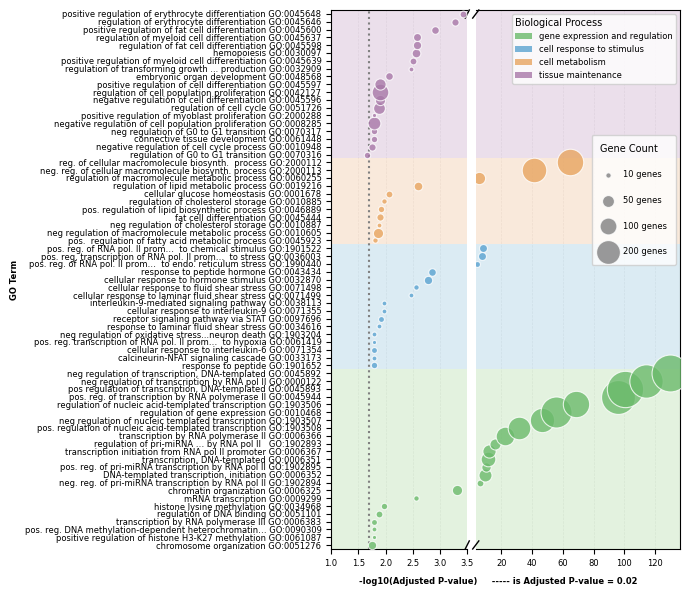

In [7]:
# Calculate -log10(adjusted p-value) - handle zeros and very small values
df['-log10(Adj_P)'] = -np.log10(df['Adjusted P-value'].replace(0, np.nan))
# Drop any rows where -log10(Adj_P) is inf or nan
df = df[np.isfinite(df['-log10(Adj_P)'])].copy()

# Extract gene count from 'Overlap' column - remove leading underscore and split
df['Gene_Count'] = df['Overlap'].apply(lambda x: int(str(x).lstrip('_').split('/')[0]))

# Calculate median -log10(Adj_P) for each category to determine category order
category_order = df.groupby('Biological Process')['-log10(Adj_P)'].median().sort_values(ascending=False).index.tolist()

# Create a categorical type with the specified order
df['Biological Process'] = pd.Categorical(df['Biological Process'], categories=category_order, ordered=True)

# Sort by category (now ordered by median p-value) and then by -log10(Adj_P) within each category
# CHANGED: ascending=[True, True] instead of [True, False] to reverse within-category order
df = df.sort_values(['Biological Process', '-log10(Adj_P)'], ascending=[True, True]).copy()

# RESET INDEX after sorting
df = df.reset_index(drop=True)

# Get the actual max value for setting limits
max_pval = df['-log10(Adj_P)'].max()

############
# Create the plot with broken axis - ROTATED 90 degrees (horizontal split)
# KEEPING original figure size (6.85, 5)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4.5, 7.0), sharey=True, #constrained_layout = True,
                                gridspec_kw={'width_ratios': [1, 1.5], 'wspace': 0.05})
############
# Define colors for each category - FROM YOUR IMAGE
# Background colors (pastel shades)
background_colors = {
    'cell metabolism': '#f4d4b8',           # Peach/tan color
    'cell response to stimulus': '#b8d8e8',  # Light blue color
    'gene expression and regulation': '#c8e6c0',  # Light green color
    'tissue maintenance': '#d8c0d8',         # Light purple/lavender color
}

# Dot colors (darker, more saturated versions for contrast)
dot_colors = {
    'cell metabolism': '#e8a560',           # Darker peach/orange
    'cell response to stimulus': '#5ba3d0',  # Darker blue
    'gene expression and regulation': '#6bba6b',  # Darker green
    'tissue maintenance': '#a878a8',         # Darker purple
}

# Get y-axis limits for full-height backgrounds
y_min, y_max = -0.5, len(df) - 0.5

# Add colored background for categories - find contiguous sections
current_category = None
start_pos = 0
for i, row in df.iterrows():
    category = row['Biological Process']
    
    # If category changes or we're at the end
    if category != current_category:
        # Draw the previous section if it exists
        if current_category is not None and current_category in background_colors:
            ax1.axhspan(start_pos - 0.5, i - 0.5,
                      facecolor=background_colors[current_category], alpha=0.5)
            ax2.axhspan(start_pos - 0.5, i - 0.5,
                      facecolor=background_colors[current_category], alpha=0.5)
        
        # Start new section
        current_category = category
        start_pos = i

# Draw the final section
if current_category is not None and current_category in background_colors:
    ax1.axhspan(start_pos - 0.5, len(df) - 0.5,
              facecolor=background_colors[current_category], alpha=0.5)
    ax2.axhspan(start_pos - 0.5, len(df) - 0.5,
              facecolor=background_colors[current_category], alpha=0.5)

# Set y-axis limits to match background spans (removes white space)
ax1.set_ylim(y_min, y_max)
ax2.set_ylim(y_min, y_max)

# Plot each point ONLY in the appropriate axis based on x-value (rotated)
for position, (idx, row) in enumerate(df.iterrows()):
    color = dot_colors.get(row['Biological Process'], '#868e96')
    x_val = row['-log10(Adj_P)']
    
    # Only plot on left axis if x-value is between 0-3.5
    if x_val <= 3.5:
        ax1.scatter(x_val, position,
                  s=row['Gene_Count']*3,
                  c=color, 
                  alpha=0.8,
                  edgecolors='white',
                  linewidth=0.8,
                  zorder=3)
    # Only plot on right axis if x-value is > 3.5
    else:
        ax2.scatter(x_val, position,
                  s=row['Gene_Count']*3,
                  c=color, 
                  alpha=0.8,
                  edgecolors='white',
                  linewidth=0.8,
                  zorder=3)

# Set the x-axis limits - break at 3.5
ax1.set_xlim(1.0, 3.5)  # Left plot shows 0-3.5
ax2.set_xlim(3.5, max_pval * 1.05)  # Right plot shows 3.5 to max (with 5% padding)

# Add vertical dotted line at Adj P-value = 0.02
# -log10(0.02) = 1.699
threshold_line = -np.log10(0.02)
# Only draw on ax1 since 1.699 < 3.5
ax1.axvline(x=threshold_line, color='gray', linestyle=':', linewidth=1.5, zorder=2)

# Hide the spines between ax1 and ax2
ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax1.yaxis.tick_left()
ax2.yaxis.tick_right()
ax2.yaxis.set_ticks_position('none')  # Remove tick marks at right
ax2.tick_params(labelright=False)  # Don't put tick labels at the right

# Set x-axis tick label font size to 6
ax1.tick_params(axis='x', labelsize=6)
ax2.tick_params(axis='x', labelsize=6)

# Add diagonal lines to indicate the break
d = .015  # Size of diagonal lines
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False, linewidth=1)
ax1.plot((1 - d, 1 + d), (0, 0 + d), **kwargs)
ax1.plot((1 - d, 1 + d), (1 - d, 1), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (0, 0 + d), **kwargs)
ax2.plot((-d, +d), (1 - d, 1), **kwargs)

# Set axes labels
fig.text(0.5, 0.06, '-log10(Adjusted P-value)     ----- is Adjusted P-value = 0.02 ', ha='center', fontsize=6, fontweight='bold')
ax1.set_ylabel('GO Term', fontsize=6, fontweight='bold')

# Add grid to both axes
ax1.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.5)
ax2.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.5)
ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

# Set y-axis labels - NO TRUNCATION
ax1.set_yticks(range(len(df)))
ax1.set_yticklabels(df['Term_short'], fontsize=6)
#ax1.set_yticklabels(df['Term'], fontsize=6)  # Using full labels without truncation

# Create legend for categories - at upper right
from matplotlib.patches import Patch
# Only include categories that have colors defined
category_patches = [Patch(facecolor=dot_colors[cat], alpha=0.8, label=cat)
                   for cat in category_order if cat in dot_colors]
legend2 = ax2.legend(handles=category_patches, title='Biological Process',  
                   title_fontsize=7, fontsize=6,
                   loc='upper right', bbox_to_anchor=(1.0, 1.0))
legend2._legend_box.align = "left"
legend2.get_title().set_horizontalalignment('left')

# Create legend for dot sizes
legend_sizes = [10, 50, 100, 200]
legend_elements = [plt.scatter([], [], s=size*3, c='gray', alpha=0.8, edgecolors='white', linewidth=0.8) 
                  for size in legend_sizes]
legend1 = ax2.legend(legend_elements, [f'{size} genes' for size in legend_sizes],
                   scatterpoints=1, frameon=True, labelspacing=2.0,
                   title='Gene Count', 
                   title_fontsize=7, fontsize=6, markerscale=0.7,
                   borderpad=1.0,
                   loc='lower right', bbox_to_anchor=(1.0, 0.52))
legend1._legend_box.align = "left"
legend1.get_title().set_horizontalalignment('left')

# Add first legend back
ax2.add_artist(legend2)

plt.tight_layout()
#plt.savefig(DATA_OUT_DIR + 'GO_enrichment_dotplot_rotated.png', dpi=300, bbox_inches='tight')
#plt.savefig(DATA_OUT_DIR + 'GO_enrichment_dotplot_rotated.png', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(DATA_OUT_DIR + 'Fig3.pdf', bbox_inches='tight')
#plt.savefig(DATA_OUT_DIR + 'Fig3.png')||
#plt.show()

# Table for cell types and tissue cell types

In [8]:
# read the meta-data
SHARED_DATA_DIR = '/oak/stanford/groups/quake/shared/TabulaSapiensTSP1_30_Paper2_Version2d_Oct2024/full_object/'
META_DATA_ALL = 'TSP1_30_metadata_min200_2500_decontx_scvi_donorassay_version2d_20241112.csv'

metadata_df_all = pd.read_csv(SHARED_DATA_DIR + META_DATA_ALL)
metadata_df_10x = metadata_df_all[metadata_df_all.method == '10X']

/tmp/ipykernel_15039/3543132001.py:5: DtypeWarning: Columns (5,6,7,8,9,13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata_df_all = pd.read_csv(SHARED_DATA_DIR + META_DATA_ALL)


In [9]:
def prune_table(df):
    df = df[['tissue', 'compartment',  'broad_cell_class', 'cell_ontology_class']]
    return(df)

In [10]:
all_table_data = prune_table(metadata_df_all)

In [11]:
all_df = all_table_data[[ 'tissue', 'broad_cell_class', 'cell_ontology_class']].groupby(['tissue', 'broad_cell_class', 'cell_ontology_class']).size().rename('CellCount').reset_index()
all_df.to_csv(DATA_OUT_DIR + 'Counts/All_701_tiss-celltypes.csv')
all_df    

,tissue,broad_cell_class,cell_ontology_class,CellCount
0,Bladder,contractile cell,myofibroblast cell,3136
1,Bladder,contractile cell,pericyte,1184
2,Bladder,contractile cell,smooth muscle cell,1053
3,Bladder,endothelial cell,capillary endothelial cell,107
4,Bladder,endothelial cell,endothelial cell,37
...,...,...,...,...
696,Vasculature,myeloid leukocyte,non-classical monocyte,1
697,Vasculature,t cell,"cd4-positive, alpha-beta t cell",728
698,Vasculature,t cell,"cd8-positive, alpha-beta t cell",1532
699,Vasculature,t cell,mature nk t cell,515


In [12]:
print(len(all_table_data[all_table_data.compartment == 'Immune'].cell_ontology_class.unique()))
print(len(all_table_data[all_table_data.compartment == 'Immune'].broad_cell_class.unique()))

45
9


In [13]:
print(len(all_table_data[all_table_data.compartment == 'Endothelium'].cell_ontology_class.unique()))
print(len(all_table_data[all_table_data.compartment == 'Endothelium'].broad_cell_class.unique()))

11
2


In [14]:
print(len(all_table_data[all_table_data.compartment == 'Epithelium'].cell_ontology_class.unique()))
print(len(all_table_data[all_table_data.compartment == 'Epithelium'].broad_cell_class.unique()))

74
18


In [15]:
print(len(all_table_data[all_table_data.compartment == 'Stromal'].cell_ontology_class.unique()))
print(len(all_table_data[all_table_data.compartment == 'Stromal'].broad_cell_class.unique()))

39
10


In [16]:
Ten_table_data = prune_table(metadata_df_10x)

In [17]:
Ten_df = Ten_table_data[['tissue', 'broad_cell_class', 'cell_ontology_class']].groupby(['tissue', 'broad_cell_class', 'cell_ontology_class']).size().rename('CellCount').reset_index()
Ten_df.to_csv(DATA_OUT_DIR + 'Counts/TenX_tiss-celltypes.csv')
Ten_df    

,tissue,broad_cell_class,cell_ontology_class,CellCount
0,Bladder,contractile cell,myofibroblast cell,3035
1,Bladder,contractile cell,pericyte,1118
2,Bladder,contractile cell,smooth muscle cell,1044
3,Bladder,endothelial cell,capillary endothelial cell,107
4,Bladder,endothelial cell,endothelial cell,17
...,...,...,...,...
658,Vasculature,myeloid leukocyte,non-classical monocyte,1
659,Vasculature,t cell,"cd4-positive, alpha-beta t cell",606
660,Vasculature,t cell,"cd8-positive, alpha-beta t cell",1450
661,Vasculature,t cell,mature nk t cell,515


In [18]:
allctcounts = pd.DataFrame(all_df.cell_ontology_class.value_counts())
tenctcounts = pd.DataFrame(Ten_df.cell_ontology_class.value_counts())
counts_combined = allctcounts.join(tenctcounts, lsuffix='_all', rsuffix='_10x').fillna('')
counts_combined.to_csv(DATA_OUT_DIR + 'Counts/CellTypeCounts.csv')
counts_combined

,count_all,count_10x
cell_ontology_class,,
"cd8-positive, alpha-beta t cell",28,28.0
b cell,28,27.0
"cd4-positive, alpha-beta t cell",28,28.0
macrophage,27,27.0
neutrophil,26,25.0
...,...,...
serous cell of epithelium of trachea,1,1.0
ciliated epithelial cell,1,1.0
myometrial cell,1,1.0


In [19]:
compartment = all_table_data[[ 'compartment', 'broad_cell_class', 'cell_ontology_class']].groupby(['compartment', 'broad_cell_class', 'cell_ontology_class']).size().rename('CellCount').reset_index()
compartment.to_csv(DATA_OUT_DIR + 'Counts/Compartment.csv')
compartment    

,compartment,broad_cell_class,cell_ontology_class,CellCount
0,Endothelium,cardiac endothelial cell,cardiac endothelial cell,10092
1,Endothelium,endothelial cell,capillary endothelial cell,15298
2,Endothelium,endothelial cell,colon endothelial cell,348
3,Endothelium,endothelial cell,endothelial cell,33703
4,Endothelium,endothelial cell,endothelial cell of arteriole,132
...,...,...,...,...
176,Stromal,stem cell,skeletal muscle satellite stem cell,6170
177,Stromal,stromal cell,stromal cell,3458
178,Stromal,stromal cell,stromal cell of ovary,35003
179,Stromal,stromal cell,tendon cell,420


In [20]:
compartcount = pd.DataFrame(compartment.compartment.value_counts())
compartcount.columns = ['celltype count']
compartcount.to_csv(DATA_OUT_DIR + 'Counts/CompartmentCount.csv')
compartcount

,celltype count
compartment,
Epithelium,74
Immune,45
Stromal,39
Endothelium,11
Neural,7
Germline,5


In [21]:
result = (all_df.groupby('broad_cell_class')['cell_ontology_class']
            .nunique()
            .reset_index()
            .rename(columns={'cell_ontology_class': 'unique_cell_ontology_count'}))
result.to_csv(DATA_OUT_DIR + 'Counts/All_celltype_to_broad_celltype.csv')
result

,broad_cell_class,unique_cell_ontology_count
0,adventitial cell,1
1,cardiac endothelial cell,1
2,ciliated epithelial cell,3
3,conjunctival epithelial cell,1
4,connective tissue cell,1
5,contractile cell,14
6,dendritic cell,2
7,duct epithelial cell,4
8,ecto-epithelial cell,4
9,endo-epithelial cell,7


In [22]:
result = (Ten_df.groupby('broad_cell_class')['cell_ontology_class']
            .nunique()
            .reset_index()
            .rename(columns={'cell_ontology_class': 'count of cell_ontology_class'}))
result.to_csv(DATA_OUT_DIR + 'Counts/TenX_celltype_to_broad_celltype.csv')
result

,broad_cell_class,count of cell_ontology_class
0,adventitial cell,1
1,cardiac endothelial cell,1
2,ciliated epithelial cell,3
3,conjunctival epithelial cell,1
4,connective tissue cell,1
5,contractile cell,14
6,dendritic cell,2
7,duct epithelial cell,4
8,ecto-epithelial cell,4
9,endo-epithelial cell,7
